In [1]:
import torch
from torch import nn

In [ ]:
# weight와 bias 확인
x = torch.randn(100,3)
layer = nn.Linear(3,5)
print(x.shape)
print(layer(x).shape)
print(layer.weight)     # 초기값 랜덤(nn.Linear)
print(layer.bias)

torch.Size([100, 3])
torch.Size([100, 5])
Parameter containing:
tensor([[ 0.4714, -0.4695, -0.3412],
        [-0.0023, -0.5719,  0.3234],
        [ 0.5094, -0.3298,  0.2833],
        [-0.0240, -0.4395, -0.3035],
        [-0.4345,  0.1016, -0.2619]], requires_grad=True)
Parameter containing:
tensor([-0.2112,  0.1006, -0.2977,  0.4816,  0.1301], requires_grad=True)


In [ ]:
x = torch.randn(2,5)
layer = nn.ReLU()
print(x)
print(layer(x))     # nn.ReLU() -> 음수는 0, 양수는 x값 그대로

tensor([[ 0.7418,  2.0066,  0.0623,  0.0037,  0.6158],
        [ 0.7813, -1.0051,  1.1716,  0.6811, -1.2187]])
tensor([[0.7418, 2.0066, 0.0623, 0.0037, 0.6158],
        [0.7813, 0.0000, 1.1716, 0.6811, 0.0000]])


In [ ]:
# weight와 bias가 랜덤이 아니고 평균 0, 표준편차 1로 표준화를 먼저함
layer = nn.BatchNorm1d(3)
print(layer.weight)     
print(layer.bias)

x = torch.randn(5,3)
print(x)
print(layer(x))
print(layer(x).mean(dim=0))
print(layer(x).std(dim = 0, unbiased = False))      # layer(x)의 출력 텐서에서 0번 차원을 기준으로 각 위치의 표준편차를 계산하되, 분모를 N으로 사용하여 계산한다

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[ 0.0728,  0.8672, -0.4658],
        [-0.1941, -0.9653, -0.0565],
        [ 0.0307, -0.6774,  0.2722],
        [ 1.4867, -1.3007,  0.5647],
        [ 0.6842,  0.9867, -1.8413]])
tensor([[-0.5632,  1.1349, -0.1908],
        [-1.0013, -0.7817,  0.2959],
        [-0.6324, -0.4805,  0.6866],
        [ 1.7569, -1.1325,  1.0344],
        [ 0.4400,  1.2599, -1.8261]], grad_fn=<NativeBatchNormBackward0>)
tensor([0.0000e+00, 4.7684e-08, 0.0000e+00], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [ ]:
layer = nn.LayerNorm(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3)
print(layer(x).mean(dim=0))
print(layer(x).std(dim = 0, unbiased = False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([ 0.4818, -0.3982, -0.0837], grad_fn=<MeanBackward1>)
tensor([0.3924, 1.1993, 1.0049], grad_fn=<StdBackward0>)


In [30]:
layer = nn.BatchNorm2d(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3,32,32)
print(layer(x).mean(dim= (0, 2,3)))     # 각 채널 별 평균
print(layer(x).std(dim=(0,2,3), unbiased = False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([-7.0781e-09,  2.7008e-09, -1.3039e-08], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [32]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [33]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN'
dataset = 'CIFAR10'

save_model_path = f'results/{model_type}_{dataset}.pt'

In [106]:
def square(x):
    return x**2

In [115]:
transform_train = transforms.Compose([
    # ------ 이미지 크기 및 영역 조절 ------
    # transforms.Resize(size = (20,20)),          # 사이즈 (32,32)에서 (20,20)으로 변경

    # transforms.CenterCrop(size = (20,20)),      # 가운데를 중심으로 (20, 20)만 남기고 테두리 자름

    # transforms.RandomCrop(size = (20,20)),      # 랜덤한 위치를 중심으로 (20,20)만 남기고 테두리 자름
    # transforms.Pad(6),                          # 상하좌우 6칸을 검정색으로 채움(Resize나 Crop이랑 같이 써주고 잘린만큼 검정으로 채울 때 사용)

    # ------ 조건부 이미지 변환 ------
    # transforms.RandomApply(
    #     nn.ModuleList([
    #         transforms.CenterCrop(size =(20,20)),
    #         transforms.Pad(6)
    #     ]), p = 0.5     # 50%의 확률로 실행(데이터의 절반이 아닌 확률이 50%)
    # ),

    # transforms.RandomResizedCrop(
    #     size = (32,32),         # 최종 이미지 크기
    #     scale = (0.3,1),        # 원본 이미지 크기의 30%~100% 범위 크롭
    #     ratio = (0.3, 1,7)      # 크롭 영역의 가로세로 비율 범위
    # ),

    #------ 색상 및 밝기 변환 ------
    # transforms.RandomGrayscale(p=0.5),      # 흑백 변환(50% 확률)

    # transforms.ColorJitter(
    #     brightness=0.3,     # 밝기
    #     contrast = 0.3,     # 대비
    #     saturation = 0.5,  # 채도
    #     hue = 0.15          # 색조
    # ),
    
    # transforms.RandomAutocontrast(p=0.5),     # 이미지의 대비(Contrast)를 무작위로 조정하는 데이터 증강(Data Augmentation) 기법

    # transforms.RandomEqualize(p=0.5),         # 히스토그램의 누적 분포를 활용해 밝기 분포를 재조정

    # transforms.RandomInvert(p=0.5),             # 색상별로 반전

    # transforms.RandomSolarize(threshold=200, p=0.5),        # 이미지의 특정 밝기보다 높은 픽셀 값을 반전(픽셀 값이 200 이상이면 색상을 반전)

    # transforms.RandomPosterize(bits=3, p=0.5),      
    # 일반적인 8비트 이미지는 각 색상 채널(R, G, B)마다 0~255까지 총 256단계의 값을 표현, 
    # Posterize는 이 비트 수를 줄여 색상 표현 단계를 감소, 이미지가 포스터처럼 단순하고 거칠게 보이도록 만듦

    # ------ 선명도 흐림 정도 ------
    # transforms.GaussianBlur(      # Gaussian Blur는 이미지의 각 픽셀에 대해 주변 픽셀을 참고하여 새로운 픽셀 값을 계산
    #     kernel_size=(5,5),        # 주변 5×5 픽셀 영역을 활용
    #     sigma = (0.1, 2)        # 이미지에 블러를 적용할 때마다 0.1~2 사이에서 sigma 값을 무작위로 선택
    # ),

    # transforms.RandomAdjustSharpness(
    #     sharpness_factor =1,            # 선명도 기준1(원본 선명도) -> 0이면 선명도 감소, 2: 선명도 증가
    #     p=0.5
    # ),

    # ------ 방향 및 위치 변환 ------
    # transforms.RandomHorizontalFlip(p=0.5),      # 좌우 반전

    # transforms.RandomVerticalFlip(p=0.5),        # 상하 반전

    # transforms.RandomRotation(degrees=(0,180)),       #  이미지를 무작위 각도로 회전

    # transforms.RandomAffine(        # 이미지를 무작위로 회전(Rotation), 이동(Translation), 확대·축소(Scaling)
    #     degrees=(0,30),     # 최소 회전 0도, 최대 회전 30도 사이 무작위 각도 선택
    #     translate=(0.1,0.3),        # 이미지 상하좌우 이동(가로, 세로)
    #     scale=(0.5,1.2)     # 이미지 크기 확대, 축소(원래 크기의 50% 축소~ 원래크기의 120% 확대)
    # ),

    # transforms.RandomPerspective(       # 이미지에 원근 변환(카메라로 물체를 비스듬한 각도에서 바라본 것처럼 이미지의 모양을 변형)을 무작위로 적용
    #     distortion_scale=0.6,       # 이미지가 얼마나 심하게 왜곡될 수 있는지를 결정하는 값
    #     p=0.5
    # ),

    # ------ 자동 데이터 ------
    # 증강 : 다양한 변화를 주어 학습 데이터에 다양성을 높이는 것
    # CIFAR10, IMAGENET, SVHN -> 논문에 3가지 데이터에 대해 데이터 증강을 비교하여  가장 성능이 좋은 데이터
    # transforms.AutoAugment(                         # 증강 방법을 자동으로 선택하고 적용
    #     transforms.AutoAugmentPolicy.CIFAR10),      # CIFAR-10 데이터셋에 맞춰 학습된 증강 정책 사용

    # transforms.RandAugment(),       # 여러 이미지 변환 중 일부를 무작위로 선택하여 적용

    # transforms.TrivialAugmentWide(),        # 이미지마다 회전, 밝기 변경, 색상 변경, 반전 등의 변환 중 하나를 랜덤하게 골라 적용

    # transforms.AugMix(),        # 여러 증강 기법을 무작위로 생성하고 혼합
    transforms.ToTensor(),       # 1. PIL이미지 또는 NUMPY 배열을 Tensor로 변환
                                # 2. 이미지 데이터 형태 변환 (H, W, C) -> (C, H, W)
                                # 3. 픽셀값 0~255의 값을 0~1 범위의 실수형으로 변환
    # ------ 이미지 일부 영역 제거 ------
    # transforms.RandomErasing(
    #     p=0.5,
    #     scale=(0.03, 0.3),      # 이미지 면적의 3% ~ 30% 범위로 무작위로 지움
    #     ratio=(0.3,3.3)
    # )

    # ------사용자 정의 함수 호출------
    # ToTensor()보다 뒤에 작성
    # transforms.Lambda(square),
    # square
    # transforms.Lambda(lambda x: x**2)
    # lambda x: x**2

    # ------ 정규화 ------
    transforms.Normalize(
        (0.485, 0.456, 0.406),          # (Red, Green, Blue)채널 픽셀값 평균
        (0.229, 0.224, 0.225)           # (Red, Green, Blue)채널 픽셀값 표준편차
    )
])

transform_test = transforms.ToTensor()

train_DS = datasets.CIFAR10(root='data', train=True, download = False, transform= transform_train)
test_DS = datasets.CIFAR10(root='data', train=False, download = False, transform= transform_test)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle = True)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0007002..2.5528543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9466565..1.4896734].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3644148..2.1975338].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7240347..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8256302..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2535014].


image size = torch.Size([3, 32, 32])
image size = torch.Size([3, 32, 32])


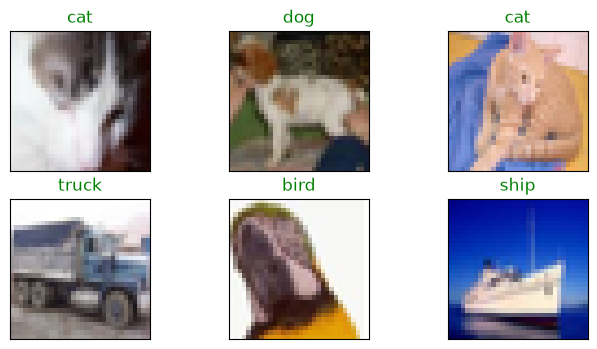

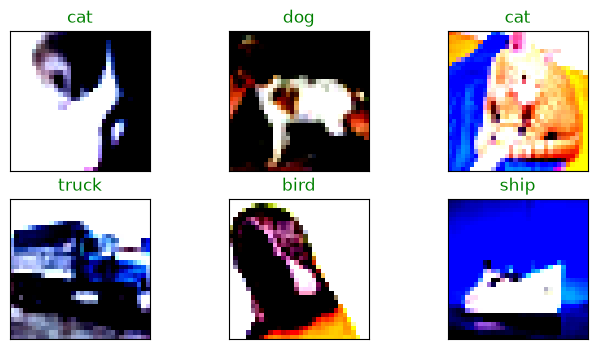

In [116]:
from PIL import Image       # PIL 파이썬 이미지 라이브러리

def im_plot(x_numpy, y_batch, transform):
    plt.figure(figsize = (8,4))
    for idx in range(6):
        im = Image.fromarray(x_numpy[idx])
        im = transform(im)

        plt.subplot(2,3, idx+1, xticks = [], yticks=[])
        plt.imshow(im.permute(1,2,0))
        true_class = test_DS.classes[y_batch[idx]]
        plt.title(true_class, color = 'g')

    print(f'image size = {im.shape}')

idx = torch.randint(0,10000,(6,))
x_batch = test_DS.data[idx]
target = torch.tensor(test_DS.targets)

y_batch = target[idx]
im_plot(x_batch, y_batch, transform_test)
im_plot(x_batch, y_batch, transform_train)

### dropout
: 오버피팅 되었을 때 학습에서 10%~30% 내외로 비활성화 해줌(비활성화 한 만큼 학습이 덜 돼서 오버피팅 막을 수 있음)

In [123]:
dropout = nn.Dropout(p=0.3)     # 비활성화 할 확률
x = torch.randint(1,101, (10,)).float()
print('원본 : ', x)

print('원본 합계 :', x.sum())
print('-'*30)

원본 :  tensor([43., 23., 91., 68., 30., 81., 93., 42., 90.,  8.])
원본 합계 : tensor(569.)
------------------------------


In [134]:
# 학습모드일 때 드롭아웃 활성화
dropout.train()     # 학습모드
train1 = dropout(x)
print('Train 1: ', train1)
print('Train1의 합계 : ', train1.sum())
print('-'*30)

train2 = dropout(x)
print('Train 2: ', train2)
print('Train1의 합계 : ', train2.sum())
print('-'*30)

train3 = dropout(x)
print('Train 3: ', train3)
print('Train1의 합계 : ', train3.sum())
print('-'*30)

# 평가모드일 때는 드롭아웃 실행 안됨
dropout.eval()
print('Eval : ', dropout(x))

Train 1:  tensor([  0.0000,  32.8571,   0.0000,   0.0000,   0.0000,   0.0000, 132.8571,
         60.0000, 128.5714,  11.4286])
Train1의 합계 :  tensor(365.7143)
------------------------------
Train 2:  tensor([ 61.4286,  32.8571, 130.0000,   0.0000,   0.0000, 115.7143,   0.0000,
         60.0000, 128.5714,   0.0000])
Train1의 합계 :  tensor(528.5714)
------------------------------
Train 3:  tensor([  0.0000,  32.8571, 130.0000,   0.0000,  42.8571, 115.7143,   0.0000,
         60.0000, 128.5714,  11.4286])
Train1의 합계 :  tensor(521.4286)
------------------------------
Eval :  tensor([43., 23., 91., 68., 30., 81., 93., 42., 90.,  8.])


In [140]:
class sample_model(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.drop_layer = nn.Sequential(nn.Linear(5,7),
                                        nn.Dropout(p=0.2)
                                        )

    def forward(self, x):
        x = self.drop_layer(x)
        return x

model = sample_model()
model.train()
x = torch.randn(2,3,5)
print(x)
print(model(x))

model.eval()
print(model(x))

tensor([[[-0.3889,  0.0292,  0.4113,  1.6503,  0.0837],
         [ 0.1334,  0.6061, -0.2747, -0.5364,  2.2859],
         [ 0.7472,  0.8116, -0.1003, -2.0578,  0.2341]],

        [[ 0.1496,  0.6507, -0.7495, -0.4487,  0.8493],
         [-0.6829,  0.6069,  0.3250, -1.3477, -0.0987],
         [-0.4512,  1.1223,  0.8300,  1.8480, -0.6008]]])
tensor([[[ 0.2265,  0.1837,  0.0000, -0.0000, -0.7561,  0.0000, -0.0000],
         [ 1.1787,  0.0000, -1.9257,  0.0000,  0.8883,  1.2785,  1.3218],
         [ 0.0000,  1.0134, -0.0000,  0.0000,  1.2792,  0.0000,  0.0000]],

        [[ 1.0924,  1.4128, -0.0000,  0.8626,  0.9581,  1.2607,  0.6224],
         [ 0.2510,  0.0686, -1.2618, -0.0812,  0.7617, -0.0419,  0.2526],
         [ 0.0707, -0.0763,  0.0000, -0.4635, -0.9073,  0.5739, -0.4216]]],
       grad_fn=<MulBackward0>)
tensor([[[ 0.1812,  0.1469,  0.1653, -0.4086, -0.6049,  0.3485, -0.3463],
         [ 0.9430,  1.4434, -1.5405,  1.0423,  0.7107,  1.0228,  1.0574],
         [ 0.5827,  0.8107, -1.42

In [141]:
class sample_model(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.drop_layer = nn.Sequential(nn.Conv2d(3,3,3),
                                        nn.Dropout2d(p=0.3))

    def forward(self, x):
        x = self.drop_layer(x)
        return x

model = sample_model()
model.train()
x = torch.randn(5,3,4,4) 
print(model(x))

tensor([[[[ 1.1411, -0.1154],
          [ 2.0763, -0.2535]],

         [[-0.7439, -0.0715],
          [-0.4491, -1.1136]],

         [[ 2.0468, -0.8421],
          [-0.7565,  0.9426]]],


        [[[-0.3105,  0.7640],
          [ 0.2891,  0.6945]],

         [[-0.5012,  0.2185],
          [-0.9571, -1.0942]],

         [[ 0.7321, -0.9823],
          [-2.3993,  1.5460]]],


        [[[-0.0000, -0.0000],
          [-0.0000, -0.0000]],

         [[-0.9427,  0.4642],
          [-0.4048, -1.9033]],

         [[-0.0000, -0.0000],
          [ 0.0000, -0.0000]]],


        [[[ 0.3392,  0.8011],
          [ 0.6784,  1.5499]],

         [[ 0.2285, -0.4251],
          [-0.2018, -0.9490]],

         [[-0.6600, -1.5826],
          [-0.8264,  0.4951]]],


        [[[ 0.0000, -0.0000],
          [ 0.0000,  0.0000]],

         [[-1.6035,  0.7466],
          [ 1.6297, -0.0266]],

         [[ 0.9727,  0.8160],
          [ 0.4468, -0.1020]]]], grad_fn=<MulBackward0>)
